In [1]:
import numpy as np

In [2]:
X = np.array([1,2,3,4])
Y = np.array([2,3,4,5])

In [6]:
# ---------------------------------------------------------
# Step 1: The data
# ---------------------------------------------------------
x_vals = [1, 2, 3, 4]
y_vals = [2, 3, 5, 4]
 


- Step 1: The Model — Making a Prediction

- Purpose: Before you can measure error, you need something to be wrong about. This step defines how the model turns an input into a prediction.

- Formula: y^ = wX + b


In [7]:
# ---------------------------------------------------------
# Step 2: The model — prediction
# ---------------------------------------------------------
def predict(x, w, b):
    return w * x + b

- Step 2: Error — Measuring How Wrong One Prediction Is

- Purpose: You need a number that captures the gap between what the model said and what's actually true, for a single data point. This is the atomic unit everything else is built from.

-  Formula:
- errori​=y^​i​−yi​

In [16]:
# ---------------------------------------------------------
# Step 3: Error for one point
# ---------------------------------------------------------
def error(y_pred, y_true):
    return y_pred - y_true
 



 

- Step 3: Squared Error — Making Error Usable

- Purpose: Raw errors can be positive or negative. If you just summed them, a model that's +10 off on one point and −10 off on another would look "perfect" (they cancel to 0) even though it's bad. Squaring:

- Removes the sign issue (always positive)
- Punishes big mistakes disproportionately more than small ones — this pushes the model to avoid any large miss, not just minimize on average.

- Formula:
- squared errori​=(y^​i​−yi​)2

In [17]:
# ---------------------------------------------------------
# Step 4: Squared error for one point
# ---------------------------------------------------------
def squared_error(y_pred, y_true):
    return (y_pred - y_true) ** 2

- Step 4: MSE — Summarizing Performance Across ALL Data

- Purpose: A single point's error tells you nothing about overall model quality. MSE averages the squared error across every example, giving you one number that says "how good is this model, overall, right now."

- MSE=1/m1​i1∑m​(y^​i​−yi​)2

In [9]:
# ---------------------------------------------------------
# Step 5: Mean Squared Error across all points
# ---------------------------------------------------------
def mse(x_vals, y_vals, w, b):
    m = len(x_vals)
    total = sum(squared_error(predict(x, w, b), y) for x, y in zip(x_vals, y_vals))
    return total / m
 

- Step 5: Cost Function — Reframing MSE in Terms of What We Control

- Purpose: MSE tells you how bad the model is, but doesn't tell you what to change. The cost function 
𝐽
(
𝑤
,
𝑏
)
- J(w,b) is the same math, but explicitly written as a function of 
𝑤
w and 
𝑏
b — the only two things you're allowed to adjust. This reframing is what makes the next step (optimization) possible.

- J(w,b)=2m1​i=1∑m​(wxi​+b−yi​)2

In [10]:
# ---------------------------------------------------------
# Step 6: Cost function J(w, b)  [MSE / 2]
# ---------------------------------------------------------
def cost(x_vals, y_vals, w, b):
    m = len(x_vals)
    total = sum(squared_error(predict(x, w, b), y) for x, y in zip(x_vals, y_vals))
    return total / (2 * m)

- Step 6: Gradients — Finding Which Direction Reduces Cost

- Purpose: Knowing the cost is high doesn't tell you how to fix w and b. The gradient (partial derivative) tells you the slope of the cost function at your current 
𝑤
,
𝑏
w,b — i.e., "if I nudge 
𝑤
w up a little, does cost go up or down, and by how much?" This is the compass that points toward improvement.

**Formula:**
- ∂w∂J​=m1​i=1∑m​(y^​i​−yi​)xi​∂b∂J​=m1​i=1∑m​(y^​i​−yi​)

In [11]:
# ---------------------------------------------------------
# Step 7: Gradients (partial derivatives of J)
# ---------------------------------------------------------
def gradients(x_vals, y_vals, w, b):
    m = len(x_vals)
    dw = sum((predict(x, w, b) - y) * x for x, y in zip(x_vals, y_vals)) / m
    db = sum((predict(x, w, b) - y) for x, y in zip(x_vals, y_vals)) / m
    return dw, db

- Step 7: Parameter Update — Actually Improving the Model

- Purpose: This is where learning happens. You take a small step in the opposite direction of the gradient (opposite because the gradient points toward increasing cost, and we want to decrease it). The learning rate 
𝛼
α controls how big that step is — too big and you overshoot the minimum, too small and training takes forever.

Formula:
- w:=w−α∂w∂J​b:=b−α∂b∂J​

In [12]:
# ---------------------------------------------------------
# Step 8: Parameter update rule
# ---------------------------------------------------------
def update(w, b, dw, db, alpha):
    w = w - alpha * dw
    b = b - alpha * db
    return w, b

- Step 8: Repeat Until Convergence — Iterative Refinement

- Purpose: One update rarely finds the best 
𝑤
,
𝑏
w,b — it's a small step. Repeating steps 6–7 many times lets the model gradually "walk downhill" on the cost surface until it settles near the minimum, where the gradient is close to zero (no direction improves things anymore).

Code:

In [13]:
# ---------------------------------------------------------
# Step 9: Gradient descent loop
# ---------------------------------------------------------
def gradient_descent(x_vals, y_vals, w, b, alpha, epochs, print_every=200):
    for i in range(epochs):
        dw, db = gradients(x_vals, y_vals, w, b)
        w, b = update(w, b, dw, db, alpha)
        if i % print_every == 0 or i == epochs - 1:
            c = cost(x_vals, y_vals, w, b)
            print(f"Epoch {i:5d} | w = {w:.4f} | b = {b:.4f} | cost = {c:.4f}")
    return w, b
 

In [14]:
# ---------------------------------------------------------
# Step 10 (bonus): Closed-form least squares solution
# ---------------------------------------------------------
def closed_form(x_vals, y_vals):
    m = len(x_vals)
    x_mean = sum(x_vals) / m
    y_mean = sum(y_vals) / m
    numerator = sum((x - x_mean) * (y - y_mean) for x, y in zip(x_vals, y_vals))
    denominator = sum((x - x_mean) ** 2 for x in x_vals)
    w = numerator / denominator
    b = y_mean - w * x_mean
    return w, b
 

In [15]:

# ===========================================================
# RUN EVERYTHING
# ===========================================================
if __name__ == "__main__":
    print("=" * 55)
    print("STEP A: Initial (untrained) model — w=0, b=0")
    print("=" * 55)
    w, b = 0.0, 0.0
    print(f"Initial MSE  = {mse(x_vals, y_vals, w, b):.4f}")
    print(f"Initial Cost = {cost(x_vals, y_vals, w, b):.4f}\n")
 
    print("=" * 55)
    print("STEP B: Training with Gradient Descent")
    print("=" * 55)
    w, b = gradient_descent(x_vals, y_vals, w=0.0, b=0.0,
                             alpha=0.01, epochs=2000, print_every=200)
 
    print("\n" + "=" * 55)
    print("STEP C: Final trained model (gradient descent)")
    print("=" * 55)
    print(f"w = {w:.4f}, b = {b:.4f}")
    print(f"Final MSE  = {mse(x_vals, y_vals, w, b):.4f}")
    print(f"Final Cost = {cost(x_vals, y_vals, w, b):.4f}\n")
 
    print("Predictions vs actual:")
    for x, y in zip(x_vals, y_vals):
        yp = predict(x, w, b)
        print(f"  x={x} | actual={y} | predicted={yp:.3f} | error={error(yp, y):+.3f}")
 
    print("\n" + "=" * 55)
    print("STEP D: Closed-form solution (sanity check)")
    print("=" * 55)
    w_cf, b_cf = closed_form(x_vals, y_vals)
    print(f"w = {w_cf:.4f}, b = {b_cf:.4f}")
    print(f"MSE  = {mse(x_vals, y_vals, w_cf, b_cf):.4f}")
    print(f"Cost = {cost(x_vals, y_vals, w_cf, b_cf):.4f}")
 

STEP A: Initial (untrained) model — w=0, b=0
Initial MSE  = 13.5000
Initial Cost = 6.7500

STEP B: Training with Gradient Descent
Epoch     0 | w = 0.0975 | b = 0.0350 | cost = 5.7217
Epoch   200 | w = 1.0770 | b = 0.6856 | cost = 0.2804
Epoch   400 | w = 1.0053 | b = 0.8964 | cost = 0.2554
Epoch   600 | w = 0.9521 | b = 1.0527 | cost = 0.2417
Epoch   800 | w = 0.9128 | b = 1.1685 | cost = 0.2342
Epoch  1000 | w = 0.8836 | b = 1.2543 | cost = 0.2300
Epoch  1200 | w = 0.8619 | b = 1.3179 | cost = 0.2278
Epoch  1400 | w = 0.8459 | b = 1.3651 | cost = 0.2265
Epoch  1600 | w = 0.8340 | b = 1.4000 | cost = 0.2258
Epoch  1800 | w = 0.8252 | b = 1.4259 | cost = 0.2255
Epoch  1999 | w = 0.8187 | b = 1.4450 | cost = 0.2253

STEP C: Final trained model (gradient descent)
w = 0.8187, b = 1.4450
Final MSE  = 0.4505
Final Cost = 0.2253

Predictions vs actual:
  x=1 | actual=2 | predicted=2.264 | error=+0.264
  x=2 | actual=3 | predicted=3.082 | error=+0.082
  x=3 | actual=5 | predicted=3.901 | erro

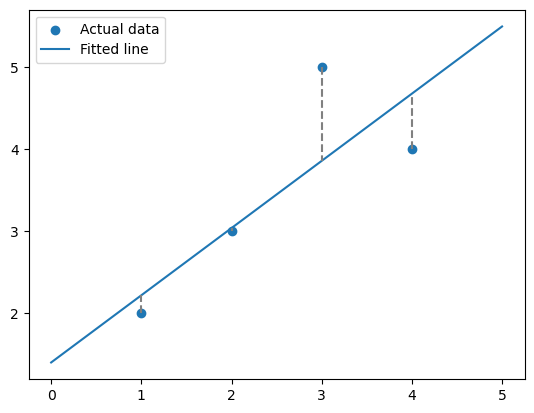

In [42]:
import matplotlib.pyplot as plt

def predict(x, w, b):
    return w * x + b

# plot the data points
plt.scatter(x_vals, y_vals, label='Actual data')
plt.legend()

# plot the line by predicting at two endpoints (a line only needs 2 points)
x_line = [0, 5]
y_line = [predict(x, w, b) for x in x_line]
plt.plot(x_line, y_line, label='Fitted line')

plt.legend()
# optional: draw vertical dashed lines showing each error
for x, y in zip(x_vals, y_vals):
    plt.plot([x, x], [y, predict(x, w, b)], linestyle='--', color='gray')

In [21]:
!pip install scikit-learn

In [23]:
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt

In [24]:
X = np.array([[1],[3],[4],[5],[7]])
Y = np.array([3,5,7,9,11])

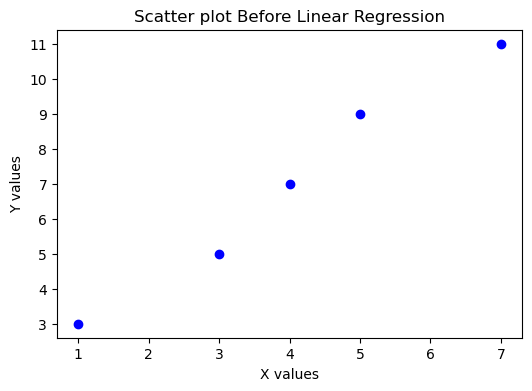

In [25]:
plt.figure(figsize=(6,4))
plt.scatter(X,Y,color='blue')
plt.title('Scatter plot Before Linear Regression')
plt.xlabel('X values')
plt.ylabel('Y values')
plt.show()

In [26]:
model = LinearRegression() # create  a linear regression model instance
model.fit(X,Y) # fit the model the data
y_pred = model.predict(X)  # predict the fitted model
print('Predicted Values:' ,y_pred)  #  print

Predicted Values: [ 2.8  5.6  7.   8.4 11.2]


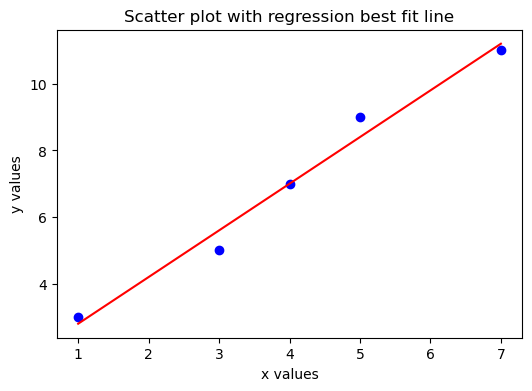

In [28]:
plt.figure(figsize=(6,4))
plt.scatter(X,Y,color='blue',label='Original Data')
plt.plot(X,y_pred,color='red',label='best fit line')
plt.xlabel('x values')
plt.ylabel('y values')
plt.title('Scatter plot with regression best fit line')
plt.show()

In [30]:
m = model.coef_
b = model.intercept_

In [31]:
print('slope (m): ',m)
print('intercept (b): ',b)

slope (m):  [1.4]
intercept (b):  1.4000000000000004
